### Book for making library

What should our tensors include?
Features which describe size of catenary curves, transmissions and phase shift.    

### 1. Pre-adjustment a project 

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import meep as mp
from IPython.display import clear_output
import conf
import math

mp.Verbosity(3) # decrease amount of output
mp.quiet()

# Pre-adjustment for MEEP
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X)]
cell = mp.Vector3(conf.cell_X, conf.cell_Y)
geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf),
    center=conf.sub_center,
)]
sources = [mp.Source(
    mp.GaussianSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=conf.source_center,
    size=mp.Vector3(y=conf.cell_Y),
)]

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    k_point=conf.k_point,
    geometry=geometry,
    sources=sources,
    resolution=conf.resolution,
)

# We count once flux_obj for the substrate for compare next with substrate - atom simulation 
flux_obj = sim.add_flux(
            conf.inc_fcen, 0, 1, mp.FluxRegion(center=conf.flux_center, size=mp.Vector3(y=conf.cell_Y))
)

sim.run(until_after_sources=50)
input_flux = mp.get_fluxes(flux_obj) # saving flux from sub in input_flux
sim.reset_meep() # purge all adjustments of simulation

FloatProgress(value=0.0, description='0% done ', max=235.0)

### 2. Setting up the library calculation

FloatProgress(value=0.0, description='0% done ', max=235.0)

step number: 0
diameter of sell: 0.0
mode_phase: -1.0805962847371071


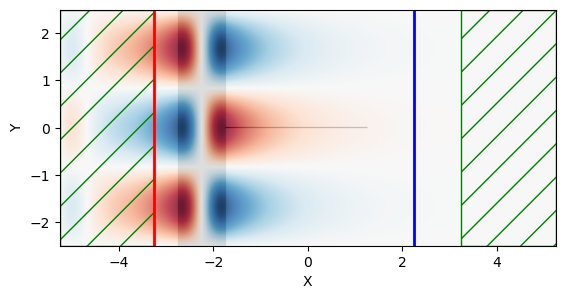

FloatProgress(value=0.0, description='0% done ', max=235.0)

step number: 1
diameter of sell: 0.020202020202020204
mode_phase: -0.9899854713219739


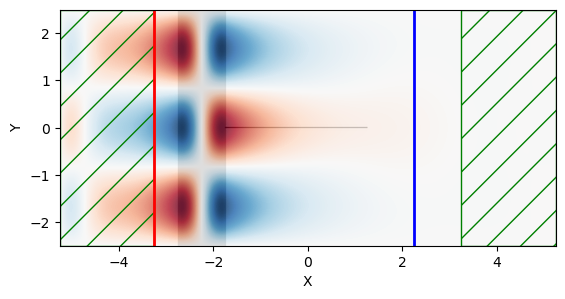

FloatProgress(value=0.0, description='0% done ', max=235.0)

step number: 2
diameter of sell: 0.04040404040404041
mode_phase: -0.6674652400410468


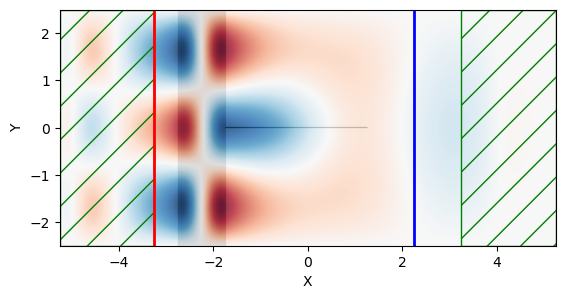

FloatProgress(value=0.0, description='0% done ', max=235.0)

step number: 3
diameter of sell: 0.06060606060606061
mode_phase: -0.5390039048779512


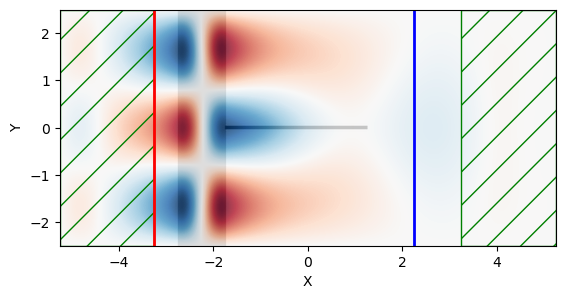

FloatProgress(value=0.0, description='0% done ', max=235.0)

step number: 4
diameter of sell: 0.08080808080808081
mode_phase: -5.699969702369856


KeyboardInterrupt: 

In [4]:
# Cell adjustment
type_of_cell = "circle"
d_min = 0 # 0 nanometers
d_max = 2 # 2 microns
split = 100 # 100 steps from d_min to d_max
d_vector = np.linspace(d_min, d_max, split)


mode_tran = np.zeros(split)
mode_phase = np.zeros(split)

# Initialisation atom geometry
geometry.append(mp.Block(
    material=conf.at_material,
    size=mp.Vector3(0,0,0),
    center=mp.Vector3(0,0,0),
))

for i in range(split):
    geometry[1].size = mp.Vector3(x=conf.at_hei, y = d_vector[i])
    geometry[1].center = conf.at_center
    sim = mp.Simulation(
        cell_size=cell,
        boundary_layers=pml_layers,
        geometry=geometry,
        sources=sources,
        resolution=conf.resolution,
    )
    
    flux_obj = sim.add_flux(
        conf.inc_fcen, 0, 1, mp.FluxRegion(
            center=mp.Vector3(x=conf.flux_center[0]), 
            size=mp.Vector3(y=conf.cell_Y)
        )
    )
    
    sim.run(until_after_sources=50)
    freqs = mp.get_eigenmode_freqs(flux_obj)
    res = sim.get_eigenmode_coefficients(
                flux_obj, [1], eig_parity=mp.ODD_Z + mp.EVEN_Y
    )
    coefficients = res.alpha
    mode_tran[i] = abs(coefficients[0, 0, 0]) ** 2 / input_flux[0]
    mode_phase[i] = np.angle(coefficients[0, 0, 0])
    if mode_phase[i] > 0:
        mode_phase[i] -= 2 * np.pi
        
    print(f'step number: {i}')
    print(f'diameter of sell: {d_vector[i]}')
    print(f'mode_phase: {mode_phase[i]}')
    
    plt.figure(dpi=100)
    sim.plot2D(fields=mp.Ez)
    plt.show()
    # if i % 10 == 0:  # Clear the output every 10 iterations
    #     clear_output(wait=True)
    

In [ ]:
mode_phase

In [ ]:
mode_tran

In [ ]:
d_vector.shape

In [ ]:
mode_tran[0]

In [ ]:
mode_phase.ndim

In [ ]:
# Plot
plt.figure(figsize=(8, 6))  
plt.plot(d_vector, mode_phase, marker='o', linestyle='-', color='b', label='Diameter to mode_phase')

plt.title('mode_phase to d', fontsize=14)
plt.xlabel('diameter in microns', fontsize=12)
plt.ylabel('mode_phase', fontsize=12)
plt.grid(True) 
plt.legend()  
plt.tight_layout() 

plt.show()

In [ ]:
# Plot
plt.figure(figsize=(6, 6))  
plt.plot(d_vector, mode_tran, marker='o', linestyle='-', color='b', label='Diameter to mode_tran')

plt.title('mode_tran to d', fontsize=14)
plt.xlabel('diameter in microns', fontsize=12)
plt.ylabel('mode_tran', fontsize=12)
plt.legend()  

plt.show()

In [ ]:
# Both on one image
from matplotlib import gridspec

# Создаем фигуру и настраиваем gridspec
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 3])  # ax2 будет в 3 раза выше, чем ax1

# Первый график (mode_tran)
ax1 = fig.add_subplot(gs[0])
ax1.plot(d_vector, mode_tran, marker='o', linestyle='-', color='r', label='Diameter to mode_tran')
ax1.set_title('mode_tran to d', fontsize=14)
ax1.set_xlabel('diameter in microns', fontsize=12)
ax1.set_ylabel('mode_tran', fontsize=12)
ax1.grid(True)
ax1.legend()

# Второй график (mode_phase)
ax2 = fig.add_subplot(gs[1])
ax2.plot(d_vector, mode_phase, marker='o', linestyle='-', color='b', label='Diameter to mode_phase')
ax2.set_title('mode_phase to d', fontsize=14)
ax2.set_xlabel('diameter in microns', fontsize=12)
ax2.set_ylabel('mode_phase', fontsize=12)
ax2.grid(True)
ax2.legend()



# Улучшаем компоновку
plt.tight_layout()

# Показать график
plt.show()

### Fine, now we want to save result as database

In [ ]:
print(mode_tran.dtype)
print(mode_tran.ndim)

In [ ]:
# Combining it into one two-dimensional array
data = np.column_stack((mode_phase, mode_tran, d_vector))

# Save it to a CSV file
np.savetxt('vectors.csv', data, delimiter=',', header='mode_phase,mode_tran,width,a', comments='', fmt='%.6f')

# Alternative: save in binary format .npy
np.save('vectors.npy', data)

print("Data saved successfully!")

In [ ]:
data.ndim

In [ ]:
data.size

In [ ]:
data.dtype

Finally. The verification is completed. The training data is calculated and stored correctly.
### TODO: Implement multithreading through parallelism of independent processes.

We have a calculated data set. But they still need to be prepared for training.
It is necessary to divide the data set into a test and a train, as well as to understand the indication of the trained parameters.